In [5]:
import pandas as pd

In [ ]:
import pandas as pd
print(pd.__version__)

2.2.3


In [6]:
url = "https://raw.githubusercontent.com/plotly/datasets/master/telco-customer-churn-by-IBM.csv"

df = pd.read_csv(url)
print(df.shape)

(7043, 21)


In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.shape

(7043, 21)

In [ ]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [1]:
df.isnull().sum()

NameError: name 'df' is not defined

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["customerID"].duplicated().sum()

np.int64(0)

In [ ]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [ ]:
churn_rate = (df["Churn"] == "Yes").mean() * 100
print("Customer Churn Rate:", round(churn_rate, 2), "%")

Customer Churn Rate: 26.54 %


In [ ]:
df.groupby("Churn")["MonthlyCharges"].mean()

,MonthlyCharges
Churn,
No,61.265124
Yes,74.441332


In [ ]:
df.groupby("Contract")["Churn"].value_counts()

Contract        Churn
Month-to-month  No       2220
                Yes      1655
One year        No       1307
                Yes       166
Two year        No       1647
                Yes        48
Name: count, dtype: int64

In [ ]:
df.groupby("Contract")

In [ ]:
df.groupby("Contract").size()

,0
Contract,
Month-to-month,3875
One year,1473
Two year,1695


In [7]:
df.groupby("Contract")["Churn"].value_counts()

Contract        Churn
Month-to-month  No       2220
                Yes      1655
One year        No       1307
                Yes       166
Two year        No       1647
                Yes        48
Name: count, dtype: int64

In [21]:
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

In [16]:
df["Churn"].value_counts(normalize=True) * 100

,proportion
Churn,


In [22]:
df.groupby("Contract")["Churn"].mean() * 100

,Churn
Contract,
Month-to-month,NaN
One year,NaN
Two year,NaN


In [19]:
url = "https://raw.githubusercontent.com/plotly/datasets/master/telco-customer-churn-by-IBM.csv"
df = pd.read_csv(url)

In [23]:
df["Churn"].value_counts(dropna=False)

,count
Churn,
NaN,7043


In [24]:
url = "https://raw.githubusercontent.com/plotly/datasets/master/telco-customer-churn-by-IBM.csv"
df = pd.read_csv(url)

In [25]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [28]:
df.groupby("Contract")["Churn"].apply(lambda x: (x == "Yes").mean() * 100)

,Churn
Contract,
Month-to-month,42.709677
One year,11.269518
Two year,2.831858


In [29]:
df.groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=False)

,Churn
Contract,
Month-to-month,42.709677
One year,11.269518
Two year,2.831858


In [30]:
churn_rate = df.groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

<Axes: xlabel='Contract'>

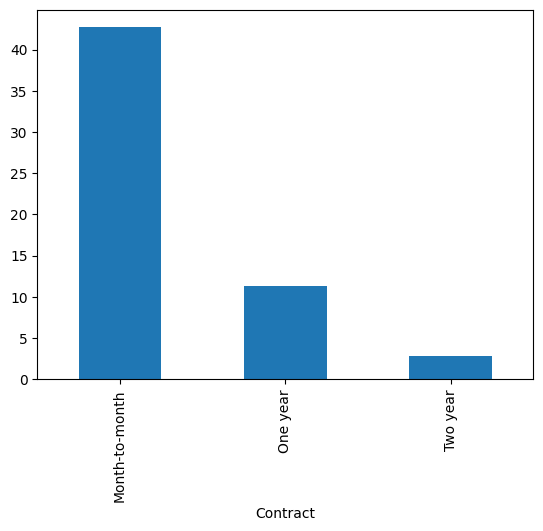

In [31]:
churn_rate.plot(kind="bar")

Text(0, 0.5, 'Churn Rate (%)')

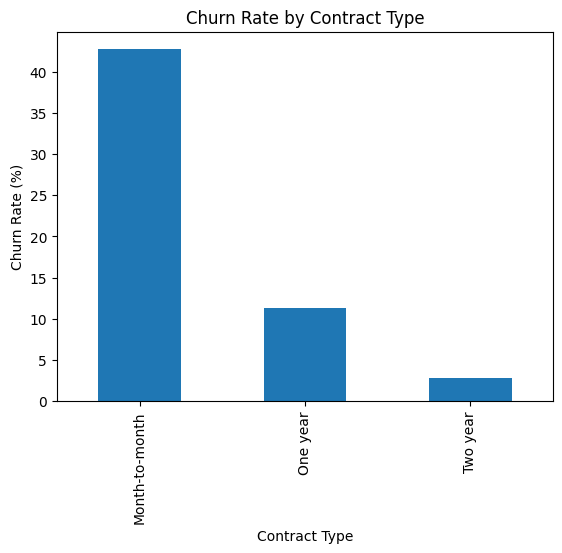

In [34]:
churn_rate.plot(kind="bar")
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

In [33]:
import matplotlib.pyplot as plt

In [35]:
plt.show()

<Axes: xlabel='Contract'>

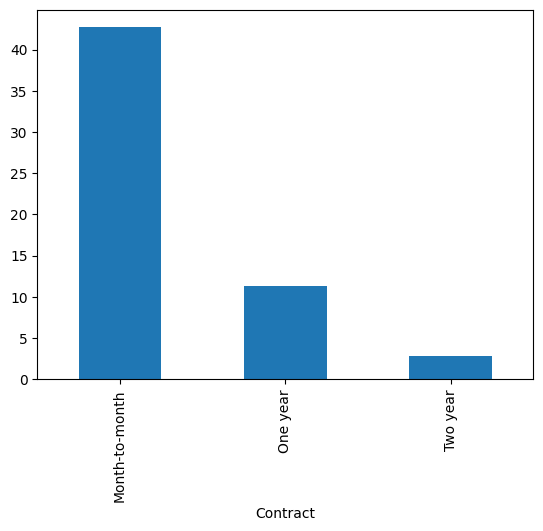

In [36]:
churn_rate.plot(kind="bar")

IndexError: list index out of range

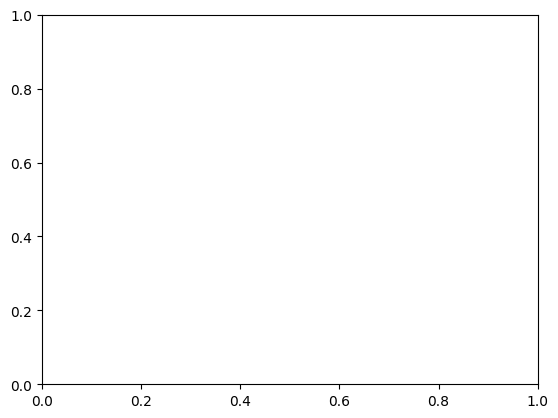

In [37]:
plt.bar_label(plt.gca().containers[0], fmt="%.1f")

<Axes: xlabel='Contract'>

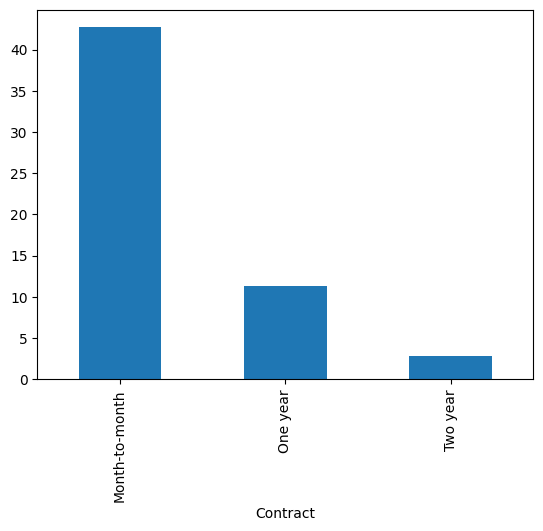

In [38]:
churn_rate.plot(kind="bar")

IndexError: list index out of range

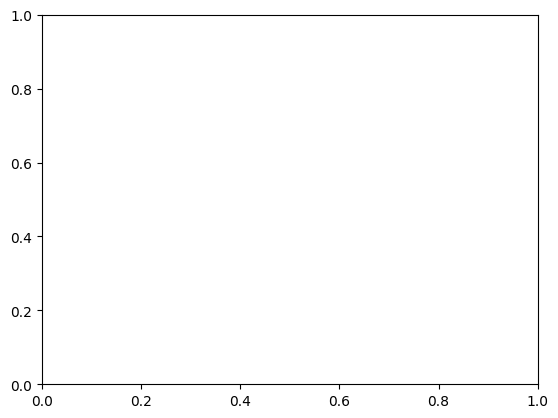

In [39]:
plt.bar_label(plt.gca().containers[0], fmt="%.1f")

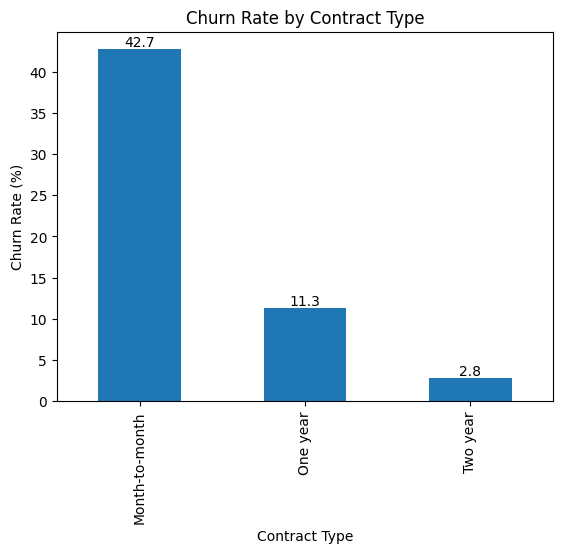

In [40]:
ax = churn_rate.plot(kind="bar")

ax.set_title("Churn Rate by Contract Type")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Churn Rate (%)")

ax.bar_label(ax.containers[0], fmt="%.1f")

plt.show()

In [41]:
(df[df["MonthlyCharges"] > 80]["Churn"] == "Yes").sum()

np.int64(906)

In [42]:
(df["MonthlyCharges"] > 80).sum()

np.int64(2666)

In [43]:
(df[df["MonthlyCharges"] > 80]["Churn"] == "Yes").mean() * 100

np.float64(33.983495873968494)

In [45]:
high_bill = df[df["MonthlyCharges"] > 80]
low_bill = df[df["MonthlyCharges"] <= 80]

print("High bill churn rate:", (high_bill["Churn"] == "Yes").mean() * 100)
print("Low bill churn rate:", (low_bill["Churn"] == "Yes").mean() * 100)

High bill churn rate: 33.983495873968494
Low bill churn rate: 22.001370801919123


In [46]:
bill_churn = pd.Series({
    "High Bill": 33.98,
    "Low Bill": 22.00
})

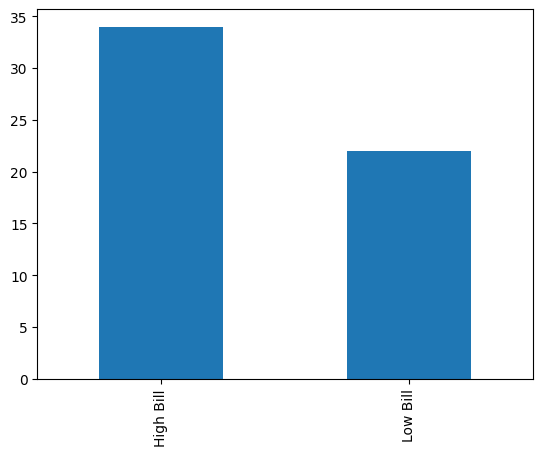

In [50]:
bill_churn.plot(kind="bar")
plt.show()

Text(0.5, 1.0, 'Churn Rate: High Bill vs Low Bill')

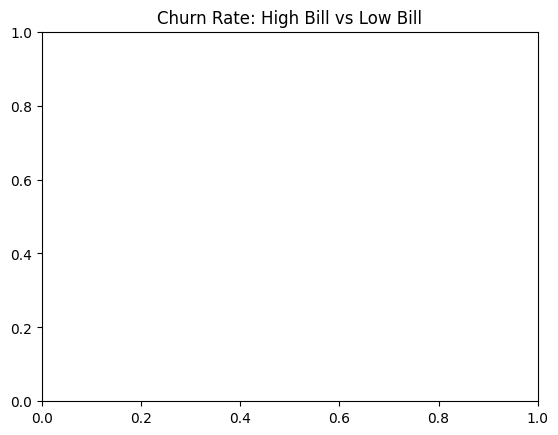

In [48]:
plt.title("Churn Rate: High Bill vs Low Bill")

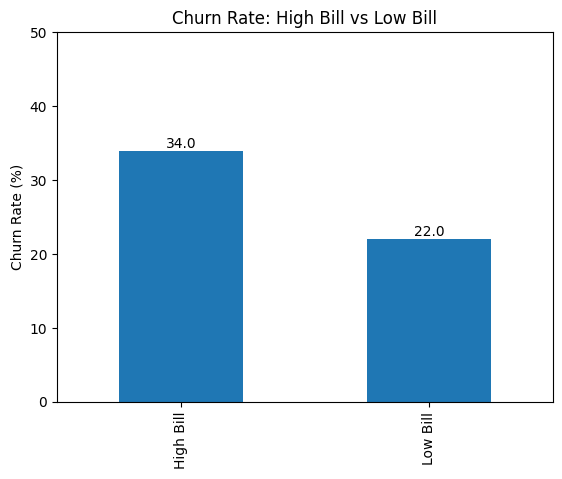

In [51]:
ax = bill_churn.plot(kind="bar", ylim=(0, 50))

ax.set_title("Churn Rate: High Bill vs Low Bill")
ax.set_ylabel("Churn Rate (%)")
ax.bar_label(ax.containers[0], fmt="%.1f")
plt.show()

In [52]:
df["tenure"].describe()

,tenure
count,7043.000000
mean,32.371149
std,24.559481
min,0.000000
25%,9.000000
50%,29.000000
75%,55.000000
max,72.000000


In [53]:
df.groupby(df["tenure"] <= 12)["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

,Churn
tenure,
False,17.129916
True,47.438243


In [54]:
tenure_churn = df.groupby(df["tenure"] <= 12)["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

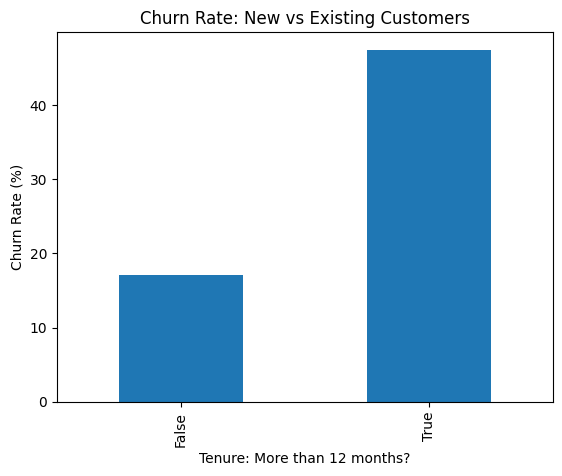

In [57]:
ax = tenure_churn.plot(kind="bar")

ax.set_title("Churn Rate: New vs Existing Customers")
ax.set_xlabel("Tenure: More than 12 months?")
ax.set_ylabel("Churn Rate (%)")

plt.show()

In [56]:
ax.bar_label(ax.containers[0], fmt="%.1f")
plt.show()

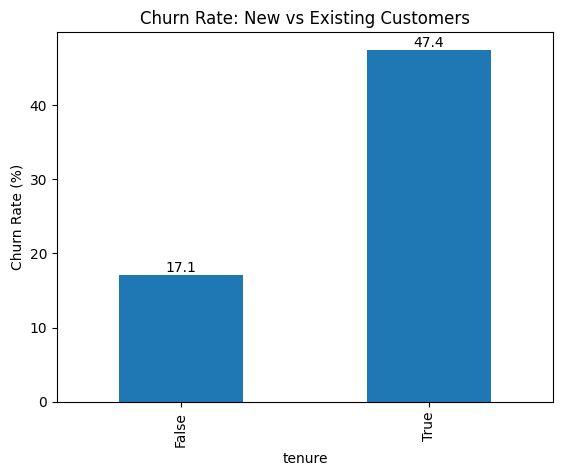

In [58]:
ax = tenure_churn.plot(kind="bar")

ax.set_title("Churn Rate: New vs Existing Customers")
ax.set_ylabel("Churn Rate (%)")

ax.bar_label(ax.containers[0], fmt="%.1f")
plt.show()

In [59]:
df["SeniorCitizen"].value_counts()

,count
SeniorCitizen,
0,5901
1,1142


In [1]:
df.groupby("SeniorCitizen")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

NameError: name 'df' is not defined

In [2]:
import pandas as pd

In [3]:
url = "https://raw.githubusercontent.com/plotly/datasets/master/telco-customer-churn-by-IBM.csv"
df = pd.read_csv(url)

In [4]:
df.shape

(7043, 21)

In [5]:
import matplotlib.pyplot as plt

In [6]:
df.groupby("SeniorCitizen")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

,Churn
SeniorCitizen,
0,23.606168
1,41.681261


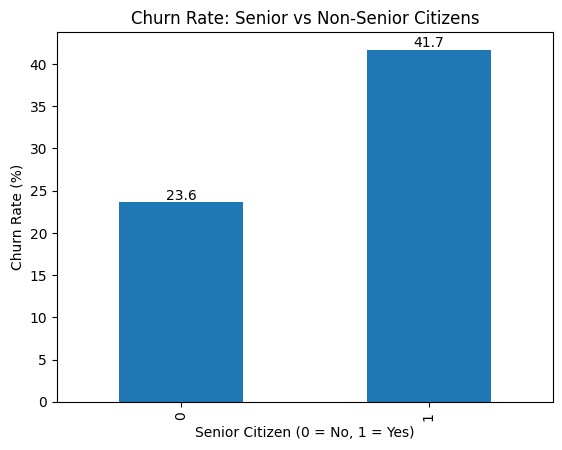

In [7]:
senior_churn = df.groupby("SeniorCitizen")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

ax = senior_churn.plot(kind="bar")
ax.set_title("Churn Rate: Senior vs Non-Senior Citizens")
ax.set_xlabel("Senior Citizen (0 = No, 1 = Yes)")
ax.set_ylabel("Churn Rate (%)")
ax.bar_label(ax.containers[0], fmt="%.1f")
plt.show()

In [8]:
df["PaymentMethod"].value_counts()

,count
PaymentMethod,
Electronic check,2365
Mailed check,1612
Bank transfer (automatic),1544
Credit card (automatic),1522


In [9]:
df.groupby("PaymentMethod")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=False)

,Churn
PaymentMethod,
Electronic check,45.285412
Mailed check,19.106700
Bank transfer (automatic),16.709845
Credit card (automatic),15.243101


In [10]:
payment_churn = df.groupby("PaymentMethod")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=False)

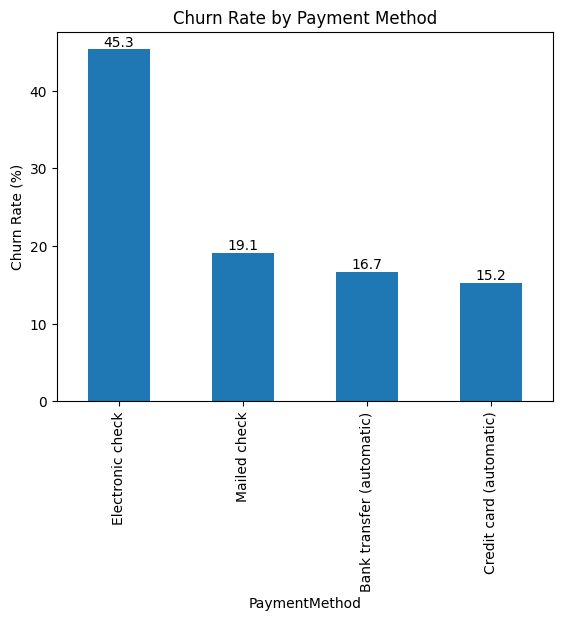

In [11]:
ax = payment_churn.plot(kind="bar")

ax.set_title("Churn Rate by Payment Method")
ax.set_ylabel("Churn Rate (%)")
ax.bar_label(ax.containers[0], fmt="%.1f")

plt.show()

In [12]:
df["InternetService"].value_counts()

,count
InternetService,
Fiber optic,3096
DSL,2421
No,1526


In [13]:
df.groupby("InternetService")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=False)

,Churn
InternetService,
Fiber optic,41.892765
DSL,18.959108
No,7.404980


In [14]:
internet_churn = df.groupby("InternetService")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=False)

In [15]:
df["PaperlessBilling"].value_counts()

,count
PaperlessBilling,
Yes,4171
No,2872


In [16]:
df.groupby("PaperlessBilling")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=False)

,Churn
PaperlessBilling,
Yes,33.565092
No,16.330084


In [17]:
paperless_churn = df.groupby("PaperlessBilling")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=False)

In [18]:
df["OnlineSecurity"].value_counts()

,count
OnlineSecurity,
No,3498
Yes,2019
No internet service,1526


In [21]:
df.groupby("OnlineSecurity")["Churn"].apply( lambda x: (x == "Yes"). mean() * 100).sort_values(ascending=False)

,Churn
OnlineSecurity,
No,41.766724
Yes,14.611194
No internet service,7.404980


In [22]:
security_churn = df.groupby("OnlineSecurity")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=False)

In [23]:
df["TechSupport"].value_counts()

,count
TechSupport,
No,3473
Yes,2044
No internet service,1526


In [24]:
df.groupby("TechSupport")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=False)

,Churn
TechSupport,
No,41.635474
Yes,15.166341
No internet service,7.404980


In [25]:
techsupport_churn = df.groupby("TechSupport")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=False)

In [26]:
df.groupby(["Contract", "InternetService"])["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=False)

Contract        InternetService
Month-to-month  Fiber optic        54.605263
                DSL                32.215863
One year        Fiber optic        19.294991
Month-to-month  No                 18.893130
One year        DSL                 9.298246
Two year        Fiber optic         7.226107
One year        No                  2.472527
Two year        DSL                 1.910828
                No                  0.783699
Name: Churn, dtype: float64

In [28]:
contract_internet_churn = df.groupby(
    ["Contract", "InternetService"]
)["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=False)

In [29]:
summary = pd.DataFrame({
    "Analysis": [
        "Contract",
        "Monthly Bill",
        "Tenure",
        "Senior Citizen",
        "Payment Method",
        "Internet Service",
        "Paperless Billing",
        "Online Security",
        "Tech Support"
    ],
    "Main Finding": [
        "Month-to-month churn: 42.71%",
        "High bill churn: 33.98%",
        "Tenure <= 12 months churn: 47.44%",
        "Senior Citizen churn: 41.68%",
        "Electronic check churn: 45.29%",
        "Fiber optic churn: 41.89%",
        "Paperless billing churn: 33.57%",
        "No online security churn: 41.77%",
        "No tech support churn: 41.64%"
    ]
})

summary

,Analysis,Main Finding
0,Contract,Month-to-month churn: 42.71%
1,Monthly Bill,High bill churn: 33.98%
2,Tenure,Tenure <= 12 months churn: 47.44%
3,Senior Citizen,Senior Citizen churn: 41.68%
4,Payment Method,Electronic check churn: 45.29%
5,Internet Service,Fiber optic churn: 41.89%
6,Paperless Billing,Paperless billing churn: 33.57%
7,Online Security,No online security churn: 41.77%
8,Tech Support,No tech support churn: 41.64%


In [30]:
summary.to_csv("churn_summary.csv", index=False)

In [31]:
recommendations = pd.DataFrame({
    "Finding": [
        "Month-to-month + Fiber optic churn: 54.61%",
        "First-year customer churn: 47.44%",
        "Electronic check churn: 45.29%",
        "No online security churn: 41.77%",
        "No tech support churn: 41.64%"
    ],
    "Recommendation": [
        "Investigate pricing and service experience",
        "Improve onboarding and early customer support",
        "Investigate billing and payment experience",
        "Explore customer security needs",
        "Review technical support quality"
    ]
})

recommendations

,Finding,Recommendation
0,Month-to-month + Fiber optic churn: 54.61%,Investigate pricing and service experience
1,First-year customer churn: 47.44%,Improve onboarding and early customer support
2,Electronic check churn: 45.29%,Investigate billing and payment experience
3,No online security churn: 41.77%,Explore customer security needs
4,No tech support churn: 41.64%,Review technical support quality


In [32]:
recommendations.to_csv("business_recommendations.csv", index=False)

In [33]:
# Objective
print("To understand why customers are leaving the company.")

To understand why customers are leaving the company.


In [34]:
# Key Findings
print("1. Month-to-month customers have the highest churn rate.")
print("2. New customers are more likely to leave the company.")
print("3. Electronic check customers have a high churn rate.")

1. Month-to-month customers have the highest churn rate.
2. New customers are more likely to leave the company.
3. Electronic check customers have a high churn rate.


In [35]:
# Business Recommendations
print("1. Encourage customers to choose longer-term contracts.")
print("2. Improve support for new customers.")
print("3. Investigate billing and payment issues.")

1. Encourage customers to choose longer-term contracts.
2. Improve support for new customers.
3. Investigate billing and payment issues.


In [36]:
# Conclusion
print("Customer churn is higher among month-to-month customers,")
print("new customers, and electronic check users.")
print("The company should investigate these patterns and")
print("test strategies to improve customer retention.")

Customer churn is higher among month-to-month customers,
new customers, and electronic check users.
The company should investigate these patterns and
test strategies to improve customer retention.


In [37]:
# Final Project Report

print("PROJECT: Customer Churn Analysis")
print("---------------------------------")

# Objective
print("\nObjective:")
print("To understand why customers are leaving the company.")

# Key Findings
print("\nKey Findings:")
print("1. Month-to-month customers: 42.71% churn")
print("2. New customers: 47.44% churn")
print("3. Electronic check users: 45.29% churn")

# Business Recommendations
print("\nRecommendations:")
print("1. Investigate contract and service experience.")
print("2. Improve onboarding for new customers.")
print("3. Investigate billing and payment experience.")

# Conclusion
print("\nConclusion:")
print("The company should investigate high-churn customer groups")
print("and test strategies to improve customer retention.")

PROJECT: Customer Churn Analysis
---------------------------------

Objective:
To understand why customers are leaving the company.

Key Findings:
1. Month-to-month customers: 42.71% churn
2. New customers: 47.44% churn
3. Electronic check users: 45.29% churn

Recommendations:
1. Investigate contract and service experience.
2. Improve onboarding for new customers.
3. Investigate billing and payment experience.

Conclusion:
The company should investigate high-churn customer groups
and test strategies to improve customer retention.


In [38]:
# Export Summary Table
summary.to_csv("churn_summary.csv", index=False)

In [39]:
# Download Summary Report
from google.colab import files
files.download("churn_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
# Check Overall Customer Churn Rate
churn_rate = (df["Churn"] == "Yes").mean() * 100

print("Overall Churn Rate:", round(churn_rate, 2), "%")

Overall Churn Rate: 26.54 %


In [41]:
# Count Customers Who Left
churned_customers = (df["Churn"] == "Yes").sum()

print("Total Churned Customers:", churned_customers)

Total Churned Customers: 1869


In [42]:
# Calculate Churn Percentage
total_customers = len(df)
churned_customers = (df["Churn"] == "Yes").sum()

churn_percentage = (churned_customers / total_customers) * 100

print("Churn Percentage:", round(churn_percentage, 2), "%")

Churn Percentage: 26.54 %


In [43]:
# Check Churn Rate by Contract Type
contract_churn = df.groupby("Contract")["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print(contract_churn.round(2))

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


In [44]:
# Contract Analysis - Business Insight
print("Month-to-month customers have the highest churn rate at 42.71%.")
print("The company should investigate their reasons for leaving.")

Month-to-month customers have the highest churn rate at 42.71%.
The company should investigate their reasons for leaving.
